# Task 1 - Time-Series Preprocessing, Exploratory Analysis & Forecasting Model
**Dataset:** Individual Household Electric Power Consumption (UCI / Kaggle) | **Target:** `Global_active_power` (hourly, kW) | **Task:** one-step-ahead forecasting

**Notebook map**
0. Problem definition and dataset justification
1. Load and understand the data (time range, frequency, structure)
2. Missing values: detect, choose a method, apply it
3. Statistical distribution of every numeric column
4. Seven analytical questions (each with a plot + interpretation; Q4 and Q5 use lagged features and moving averages)
5. Feature engineering (lags, moving averages, calendar features)
6. Modelling: baselines, 3 tuned model families, ablation, experiment table
7. Save artefacts for Task 2 / Task 3 / Task 4

> Every section has a **What / Why** box so you can explain each decision in your report or oral defence.

## 0. Problem definition and dataset justification
**Problem.** Forecast a household's electricity demand one hour ahead: given everything measured up to hour *t-1*, predict the average active power (kW) during hour *t*.

**Why this matters.** Demand forecasting lets utilities plan generation and avoid peak-load stress, and lets households and smart-home systems shift appliances to cheaper or greener hours. It is a standard real-world time-series task.

**Why this dataset satisfies the assignment checklist**

| Requirement | How the dataset meets it |
|---|---|
| Clear timestamp | `Date` + `Time`, one reading **every minute** for almost 4 years (Dec 2006 - Nov 2010) |
| Meaningful target | `Global_active_power` (forecasting / regression) |
| Multiple measurable variables | Reactive power, voltage, current intensity, and 3 sub-meters (kitchen, laundry, water heater/AC) |
| Rich temporal structure | Daily, weekly and yearly seasonality, plus missing blocks that make preprocessing a real challenge |

**Granularity choice.** Minute data (2.07 M rows) is extremely noisy and expensive to model. We aggregate to **hourly means** (34,589 rows): still fine-grained for demand forecasting, but with a clearer signal and fast experimentation.

In [1]:
import warnings, json, time, inspect
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller

import preprocessing as pp          # our reusable pipeline (also used in Task 4)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 5), "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:,.3f}".format)

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True); Path("data").mkdir(exist_ok=True)

def save_show(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

Matplotlib is building the font cache; this may take a moment.


## 1. Load and understand the data
**What:** read the semicolon-separated text file, treat `?` as missing, merge `Date` + `Time` into one `datetime` index.
**Why:** a proper `DatetimeIndex` unlocks everything time-series: resampling, rolling windows, shifting (lags), slicing by date. The file encodes missing readings as `?`; if we don't declare that, pandas would read the numeric columns as text.

In [ ]:
CANDIDATES = [Path("data/household_power_consumption.txt"),
              Path("household_power_consumption.txt")]
DATA_PATH = next(p for p in CANDIDATES if p.exists())

raw = pp.load_raw(DATA_PATH)
raw.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.000
2006-12-16 17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.000
2006-12-16 17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.000
2006-12-16 17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.000
2006-12-16 17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.000


### 1.1 Time range, frequency and structure (assignment questions A.1 and A.2)
**Why:** we need to know the *granularity* (are readings evenly spaced?) and whether timestamps are missing, because lags and rolling windows silently assume a regular grid.

In [3]:
print(f"Rows: {len(raw):,} | Columns: {raw.shape[1]}")
print("Time range :", raw.index.min(), "->", raw.index.max())
span = raw.index.max() - raw.index.min()
print(f"Span       : {span}  (~{span.days/365.25:.2f} years)")

steps = raw.index.to_series().diff().dropna().value_counts()
print("\nTime gap between consecutive rows:"); print(steps.to_string())

expected = pd.date_range(raw.index.min(), raw.index.max(), freq="min")
print(f"\nExpected minutes: {len(expected):,} | Actual rows: {len(raw):,} | Missing timestamps: {len(expected.difference(raw.index)):,}")
print("Duplicated timestamps:", raw.index.duplicated().sum())
print("\nColumn types:"); print(raw.dtypes.to_string())

Rows: 2,075,259 | Columns: 7
Time range : 2006-12-16 17:24:00 -> 2010-11-26 21:02:00
Span       : 1441 days 03:38:00  (~3.95 years)

Time gap between consecutive rows:
datetime
0 days 00:01:00    2075258

Expected minutes: 2,075,259 | Actual rows: 2,075,259 | Missing timestamps: 0
Duplicated timestamps: 0

Column types:
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64


**Data dictionary**

| Column | Meaning | Unit |
|---|---|---|
| `Global_active_power` | Household active power (the **target**) | kW (minute average) |
| `Global_reactive_power` | Household reactive power | kW |
| `Voltage` | Mains voltage | V |
| `Global_intensity` | Current intensity | A |
| `Sub_metering_1` | Kitchen (dishwasher, oven, microwave) | Wh per minute |
| `Sub_metering_2` | Laundry (washer, dryer, fridge, light) | Wh per minute |
| `Sub_metering_3` | Water heater and air conditioner | Wh per minute |
| `Sub_metering_4` *(engineered)* | Everything not on sub-meters 1-3: `GAP*1000/60 - (S1+S2+S3)` | Wh per minute |

**What we found**
* **Time range:** 16 Dec 2006 17:24 to 26 Nov 2010 21:02, about **3.95 years**.
* **Frequency:** exactly **one reading per minute**. All 2,075,258 steps between consecutive rows are 1 minute, with **no missing timestamps and no duplicates**. The time grid is perfectly regular, so any gaps are missing *values*, not missing *rows*.
* **Size and types:** 2,075,259 rows and 7 numeric sensor columns. Once `?` is declared as missing, every column loads as `float64`.
* The 7 columns plus our engineered `Sub_metering_4` give the "multiple measurable variables over time" the assignment asks for.

## 2. Missing values (assignment question A.3)
**What:** count missing readings, find *where* they sit and how long each gap is.
**Why:** the right fix depends on the **shape** of the missingness. Isolated one-minute holes can be interpolated; multi-day blackouts cannot, because a straight line across 5 days would invent a flat, unrealistic demand curve.

,missing_values,pct_of_rows
Global_active_power,25979,1.252
Global_reactive_power,25979,1.252
Voltage,25979,1.252
Global_intensity,25979,1.252
Sub_metering_1,25979,1.252
Sub_metering_2,25979,1.252
Sub_metering_3,25979,1.252


Rows where ALL sensors are missing: 25979 of 25979 rows with any missing value



Number of gaps: 71 | single-minute gaps: 38 | gaps > 1 hour: 9


,start,end,minutes,hours
run,,,,
138,2010-08-17 21:02:00,2010-08-22 21:27:00,7226,120.433
140,2010-09-25 03:56:00,2010-09-28 19:12:00,5237,87.283
14,2007-04-28 00:21:00,2007-04-30 14:23:00,3723,62.050
100,2009-06-13 00:30:00,2009-06-15 07:34:00,3305,55.083
118,2010-01-12 14:53:00,2010-01-14 19:01:00,3129,52.150
126,2010-03-20 03:52:00,2010-03-21 13:38:00,2027,33.783
104,2009-08-13 05:00:00,2009-08-13 19:50:00,891,14.850
32,2007-07-15 16:49:00,2007-07-15 18:11:00,83,1.383


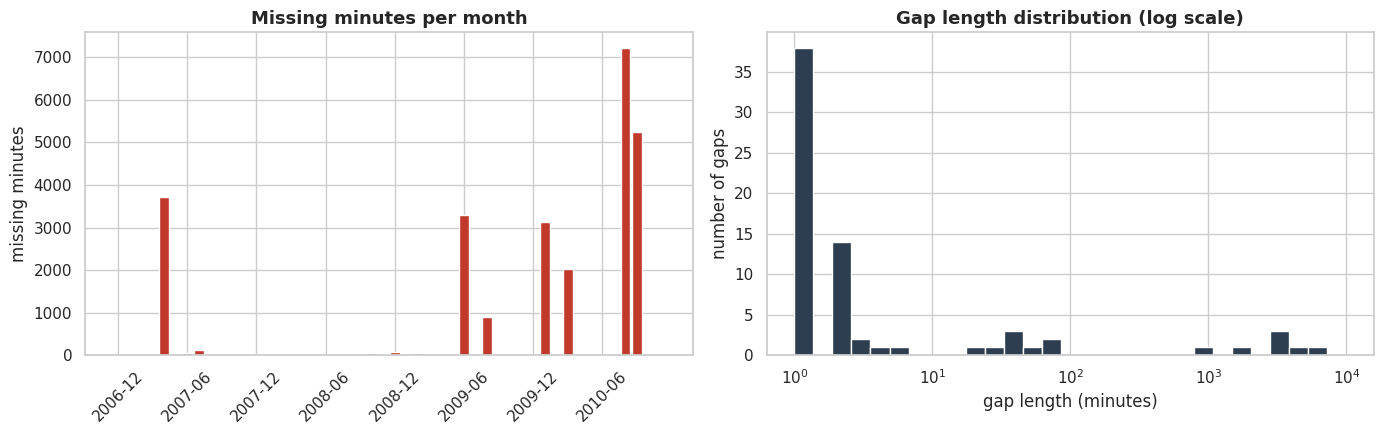

In [4]:
miss = raw.isna().sum().to_frame("missing_values")
miss["pct_of_rows"] = miss["missing_values"] / len(raw) * 100
display(miss)
print("Rows where ALL sensors are missing:", raw.isna().all(axis=1).sum(), "of", raw.isna().any(axis=1).sum(), "rows with any missing value")

# find contiguous gaps (runs of missing minutes)
isna = raw["Global_active_power"].isna()
run = (isna != isna.shift()).cumsum()
gaps = (pd.DataFrame({"isna": isna, "run": run})[isna].reset_index()
        .groupby("run").agg(start=("datetime", "first"), end=("datetime", "last"), minutes=("datetime", "size")))
gaps["hours"] = gaps["minutes"] / 60
print(f"\nNumber of gaps: {len(gaps)} | single-minute gaps: {(gaps.minutes==1).sum()} | gaps > 1 hour: {(gaps.minutes>60).sum()}")
display(gaps.sort_values("minutes", ascending=False).head(8))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
mm = isna.astype(int).resample("MS").sum()
ax[0].bar(range(len(mm)), mm.values, color="#c0392b", width=0.85)
ax[0].set_title("Missing minutes per month"); ax[0].set_ylabel("missing minutes")
ax[0].set_xticks(range(0, len(mm), 6)); ax[0].set_xticklabels([d.strftime("%Y-%m") for d in mm.index[::6]], rotation=45)
ax[1].hist(gaps["minutes"], bins=np.logspace(0, 4, 30), color="#2c3e50"); ax[1].set_xscale("log")
ax[1].set_title("Gap length distribution (log scale)"); ax[1].set_xlabel("gap length (minutes)"); ax[1].set_ylabel("number of gaps")
save_show("missing_overview")

**Interpretation**
* **25,979 minutes (1.25%) are missing, and in every case all 7 sensors are missing together.** This is the signature of a logger/communication outage, not of individual sensors failing. So we can treat gaps as whole-row events and impute all columns consistently.
* There are **71 gaps**: 38 are a single minute, but **9 last more than an hour**. The six largest gaps (up to **7,226 minutes, about 5 days, 17-22 Aug 2010**) contain about **95% of all missing minutes**; the others are 87 h (Sep 2010), 62 h (Apr 2007), 55 h (Jun 2009), 52 h (Jan 2010) and 34 h (Mar 2010).
* The missingness is therefore **two different problems**: many tiny holes (harmless) and a few multi-day blackouts (where a naive fix would distort the data). The bar chart shows the blackouts cluster in a few specific months, and the log-scale histogram shows most gaps are very short with a long tail.
* This is why a single "fill with the mean" rule would be a poor choice: the method has to depend on gap length.

### 2.1 Chosen method: aggregate to hourly, then gap-aware imputation
**What we do (3 steps)**
1. **Aggregate minutes to hourly means.** Averaging ignores NaNs inside each hour, so isolated missing minutes are absorbed automatically with no invented data.
2. **Short gaps (<= 6 hours): time-based linear interpolation.** Over a few hours demand changes smoothly, so a straight line is a reasonable estimate.
3. **Long gaps (> 6 hours): copy the value from the same hour one week earlier.** Household demand is strongly weekly-periodic (Q2), so "same hour, same weekday, last week" preserves the daily shape that a straight line would destroy.

**Why not the alternatives?** *Dropping* rows would break the regular time grid and corrupt every lag and rolling window. *Global mean/median* ignores the daily cycle (it would put a 1.1 kW average at 3 a.m. when real demand is ~0.3 kW). *Forward-fill* repeats one value for days. All sensors are missing together (same rows), so imputing each column separately is consistent.

--- Source code of the imputation function (from preprocessing.py) ---
def fill_missing_hourly(hourly, short_gap=6, season=168):
    """
    Gap-aware imputation on the hourly table.
      * gaps <= `short_gap` hours  -> time-based linear interpolation
      * longer gaps                -> same hour one week earlier (fallback: one week later)
    """
    h = hourly.copy()
    gap = h.isna().any(axis=1)
    run_id = (gap != gap.shift()).cumsum()
    run_len = gap.groupby(run_id).transform("sum")
    short = gap & (run_len <= short_gap)

    interp = h.interpolate(method="time", limit_area="inside")
    h.loc[short] = interp.loc[short]

    h = h.fillna(h.shift(season))      # same hour, previous week
    h = h.fillna(h.shift(-season))     # same hour, next week (only used at the very start)
    return h.ffill().bfill()           # safety net, should be a no-op



Hourly rows: 34,589 | hours still missing after aggregation: 421 (1.22%) in 8 gaps | short (<=6h): 1 | long: 7
Missing values BEFORE: 3368 | AFTER: 0


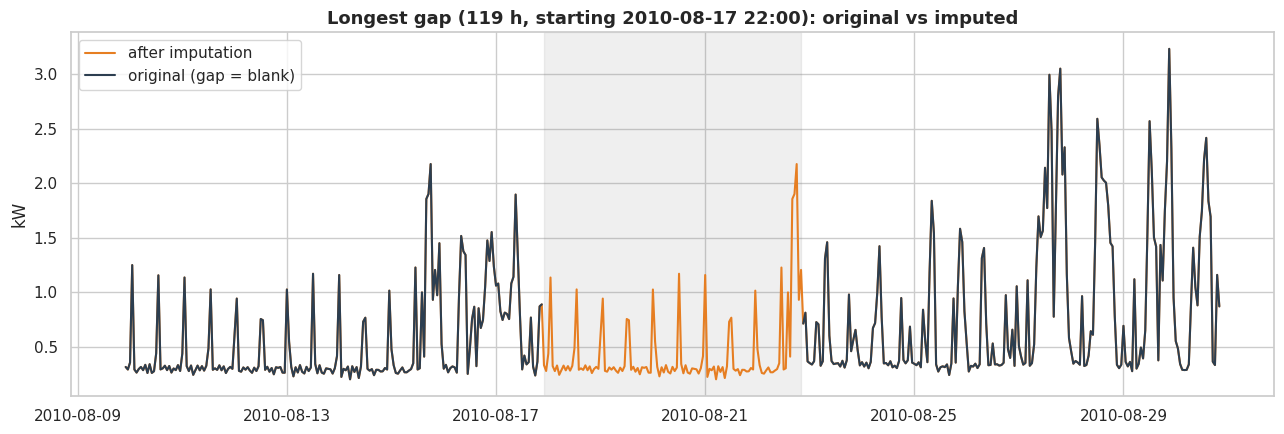

In [5]:
print("--- Source code of the imputation function (from preprocessing.py) ---")
print(inspect.getsource(pp.fill_missing_hourly))

raw4 = pp.add_unmetered(raw)                      # engineered Sub_metering_4
hourly_raw = pp.to_hourly(raw4)                   # step 1
hourly = pp.fill_missing_hourly(hourly_raw)       # steps 2-3

bad = hourly_raw.isna().any(axis=1)
rid = (bad != bad.shift()).cumsum()
hgaps = bad.groupby(rid).agg(["first", "size"]); hgaps = hgaps[hgaps["first"]]["size"]
print(f"Hourly rows: {len(hourly_raw):,} | hours still missing after aggregation: {bad.sum()} "
      f"({bad.mean()*100:.2f}%) in {len(hgaps)} gaps | short (<=6h): {(hgaps<=6).sum()} | long: {(hgaps>6).sum()}")
print("Missing values BEFORE:", int(hourly_raw.isna().sum().sum()), "| AFTER:", int(hourly.isna().sum().sum()))

# visual check on the longest gap
start = bad[bad].index[0]; 
longest_end = bad.groupby(rid).apply(lambda s: s.index[-1] if s.iloc[0] else None).dropna()
gap_len = bad.groupby(rid).agg(["first", "size"]); 
big_run = gap_len[gap_len["first"]]["size"].idxmax()
g_idx = bad[rid == big_run].index
win = slice(g_idx[0] - pd.Timedelta(days=8), g_idx[-1] + pd.Timedelta(days=8))
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(hourly.loc[win, "Global_active_power"], color="#e67e22", lw=1.5, label="after imputation")
ax.plot(hourly_raw.loc[win, "Global_active_power"], color="#2c3e50", lw=1.5, label="original (gap = blank)")
ax.axvspan(g_idx[0], g_idx[-1], color="grey", alpha=0.12)
ax.set_title(f"Longest gap ({len(g_idx)} h, starting {g_idx[0]:%Y-%m-%d %H:%M}): original vs imputed")
ax.set_ylabel("kW"); ax.legend()
save_show("imputation_check")

**Interpretation**
* Aggregating to hours made the 71 minute-level gaps collapse to just **8 hourly gaps (421 hours, 1.22%)**: the 38 one-minute holes vanish because an hour's mean simply uses its other 59 minutes. Only **1 gap is short (<= 6 h)** and **7 are long**.
* After imputation there are **0 missing values** (3,368 cells filled before, 0 after).
* The plot of the longest gap (120 hours, Aug 2010) shows why the weekly-copy method is sensible: the orange imputed curve keeps a realistic **day/night cycle with morning and evening peaks**, whereas a straight line would have produced a flat, unrealistic stretch of about 5 days.
* **Limitation to mention honestly:** imputed hours (about 1.2% of the data) are estimates, not measurements, and copying last week assumes the household behaved as usual (a holiday week, for example, would not be reproduced). With only 1.2% affected, the effect on model training is small.

## 3. Statistical distribution of the numerical columns (assignment question A.4)
**What:** summary statistics, skewness, histograms and an IQR outlier check.
**Why:** distribution shape drives modelling choices (e.g. heavy right skew means errors will be dominated by peaks; a metric such as RMSE will punish peaks hardest) and tells us whether outliers are sensor errors or genuine events.

Minute-level statistics (raw data, missing values excluded):


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Global_active_power,"2,049,280.000",1.092,1.057,0.076,0.308,0.602,1.528,11.122,1.786,4.219
Global_reactive_power,"2,049,280.000",0.124,0.113,0.000,0.048,0.100,0.194,1.390,1.262,2.606
Voltage,"2,049,280.000",240.840,3.240,223.200,238.990,241.010,242.890,254.150,-0.327,0.725
Global_intensity,"2,049,280.000",4.628,4.444,0.200,1.400,2.600,6.400,48.400,1.849,4.601
Sub_metering_1,"2,049,280.000",1.122,6.153,0.000,0.000,0.000,0.000,88.000,5.945,35.643
Sub_metering_2,"2,049,280.000",1.299,5.822,0.000,0.000,0.000,1.000,80.000,7.091,57.907
Sub_metering_3,"2,049,280.000",6.458,8.437,0.000,0.000,1.000,17.000,31.000,0.725,-1.282
Sub_metering_4,"2,049,280.000",9.315,9.586,-2.400,3.800,5.500,10.367,124.833,2.487,7.911


Hourly statistics (after preprocessing - this is what the model sees):


,count,mean,std,min,25%,50%,75%,max,skew
Global_active_power,"34,589.000",1.089,0.896,0.124,0.341,0.800,1.578,6.561,1.299
Global_reactive_power,"34,589.000",0.124,0.067,0.000,0.078,0.107,0.150,0.774,1.868
Voltage,"34,589.000",240.846,2.996,225.834,239.200,240.985,242.693,251.902,-0.322
Global_intensity,"34,589.000",4.618,3.753,0.503,1.510,3.407,6.593,28.383,1.352
Sub_metering_1,"34,589.000",1.121,3.538,0.000,0.000,0.000,0.000,48.367,4.257
Sub_metering_2,"34,589.000",1.296,4.185,0.000,0.000,0.333,0.650,46.433,5.281
Sub_metering_3,"34,589.000",6.453,7.345,0.000,0.650,1.650,14.167,21.550,0.714
Sub_metering_4,"34,589.000",9.282,8.254,1.379,4.346,5.732,11.064,64.837,2.047


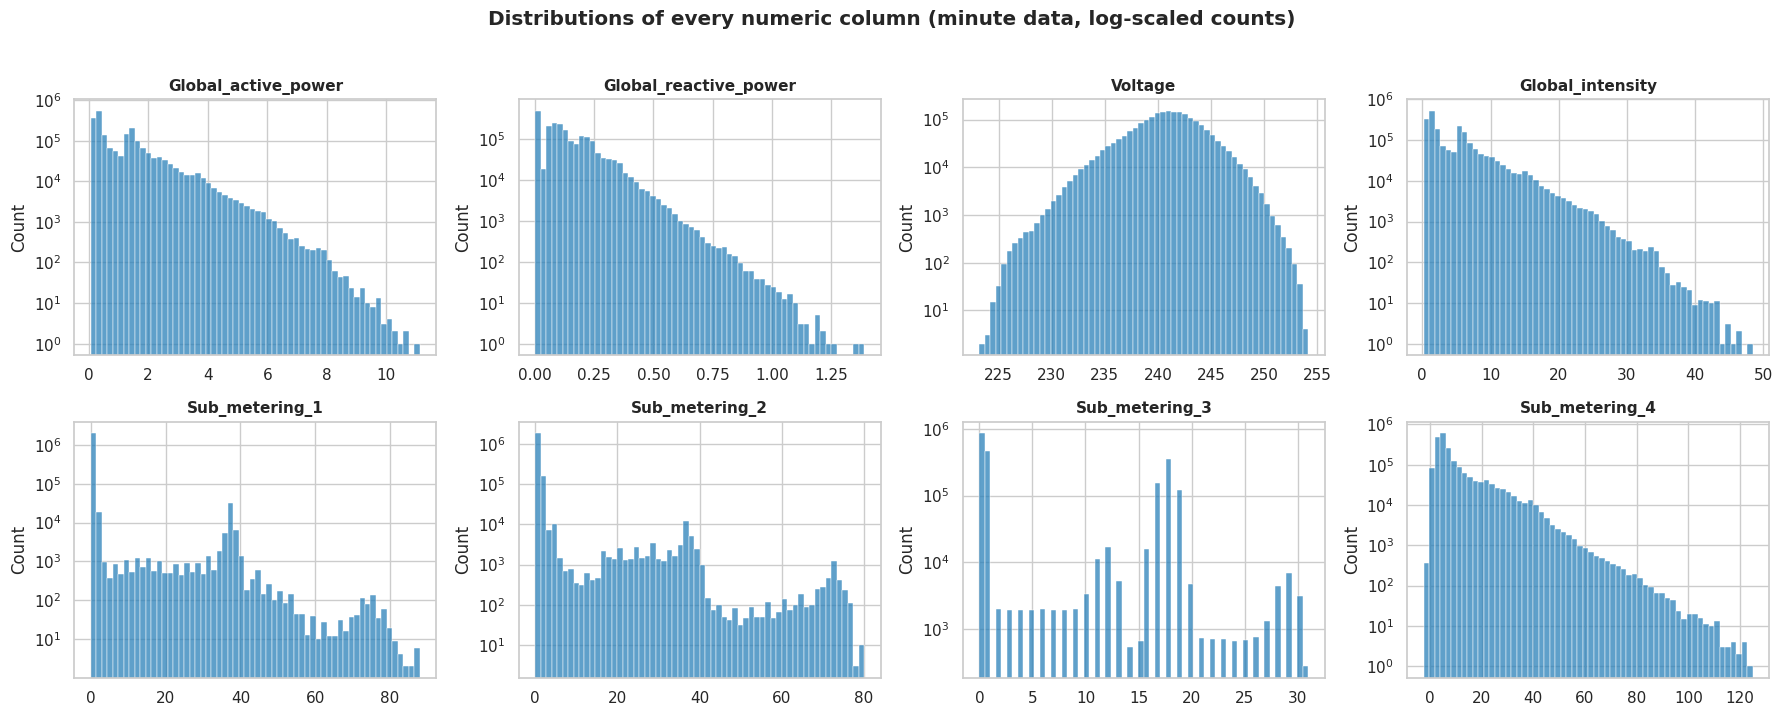

Share of hourly values flagged by the 1.5 x IQR rule (%):
Global_active_power      2.130
Global_reactive_power    4.840
Voltage                  3.240
Global_intensity         2.400
Sub_metering_1          14.420
Sub_metering_2           7.490
Sub_metering_3           0.000
Sub_metering_4          10.550


In [6]:
cols = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity",
        "Sub_metering_1", "Sub_metering_2", "Sub_metering_3", "Sub_metering_4"]
print("Minute-level statistics (raw data, missing values excluded):")
display(raw4[cols].describe().T.assign(skew=raw4[cols].skew(), kurtosis=raw4[cols].kurt()))
print("Hourly statistics (after preprocessing - this is what the model sees):")
display(hourly[cols].describe().T.assign(skew=hourly[cols].skew()))

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), cols):
    sns.histplot(raw4[c].dropna(), bins=60, ax=ax, color="#2980b9"); ax.set_title(c, fontsize=11); ax.set_xlabel("")
    ax.set_yscale("log")
fig.suptitle("Distributions of every numeric column (minute data, log-scaled counts)", fontweight="bold", y=1.02)
save_show("distributions")

q1, q3 = hourly[cols].quantile(0.25), hourly[cols].quantile(0.75); iqr = q3 - q1
out_pct = ((hourly[cols] < q1 - 1.5 * iqr) | (hourly[cols] > q3 + 1.5 * iqr)).mean() * 100
print("Share of hourly values flagged by the 1.5 x IQR rule (%):"); print(out_pct.round(2).to_string())

**Interpretation**
* **Target `Global_active_power`:** right-skewed. At minute level the mean (1.09 kW) is far above the median (0.60 kW), skew = 1.79, maximum 11.1 kW. The household is mostly in a **low-load state with occasional high peaks**. Hourly averaging shrinks the extremes (max 6.56 kW, std 0.90 vs 1.06, skew 1.30) but keeps the shape. Practical consequence: **peaks will dominate RMSE**, so we also report MAE.
* **`Voltage`:** close to a bell shape centred on about 240.8 V (std 3.2 V, range 223-254 V), slightly left-skewed (-0.33): the grid is stable, with occasional sags.
* **`Global_intensity`:** same shape as active power (skew 1.85), as expected since current drives power.
* **`Sub_metering_1` and `_2` (kitchen, laundry):** extremely zero-inflated. The median is 0 and skew is 5.9 and 7.1 with huge kurtosis (36 and 58): these appliances are **off most of the time and then draw short, large bursts**.
* **`Sub_metering_3` (water heater / AC):** not skewed like the others (kurtosis -1.28); its readings are spread between "off" and a high "on" level, consistent with a thermostat-style device cycling on and off.
* **Data-quality finding:** the engineered `Sub_metering_4` has a minimum of **-2.4 Wh/min**. Negative "unmetered" energy is physically impossible, so at those minutes the three sub-meters add up to slightly more than the global meter (measurement or rounding error between meters). It is a tiny share of the data, so we keep it, but it is worth stating in the report.
* **Outliers:** the IQR rule flags 2.1% of hourly demand values, but these are the **genuine evening peaks**, the very events we want to forecast, so we **do not remove them**. The high flagged share for the kitchen and laundry meters (14% and 7%) only reflects zero-inflation (the IQR rule is meaningless when most values are 0). Tree-based models are also robust to extreme values.

## 4. Analytical questions
Each question has: *why we ask it* -> code + visualisation -> detailed interpretation. **Q4 (lagged features) and Q5 (moving averages)** satisfy the assignment's mandatory requirement.

### Q1. Does electricity demand have a long-term increasing or decreasing trend?
**Why:** a trend means the series is not stationary, so the mean level drifts. That affects model choice and the train/test split (the test period may sit at a different level from training).
**Method:** (a) monthly average with a 12-month moving average, (b) yearly average over the *same* months (Jan-Nov) to compare fairly, (c) STL decomposition, which separates trend / seasonality / noise, and (d) an ADF stationarity test.

Mean demand over Jan-Nov of each year (kW):
datetime
2007   1.071
2008   1.053
2009   1.050
2010   1.052
Change vs previous year (%):
datetime
2007      NaN
2008   -1.600
2009   -0.400
2010    0.300



STL trend slope: -0.019 kW per year (start 1.11 -> end 1.08 kW)
ADF test on daily mean: statistic=-3.66, p-value=0.0048


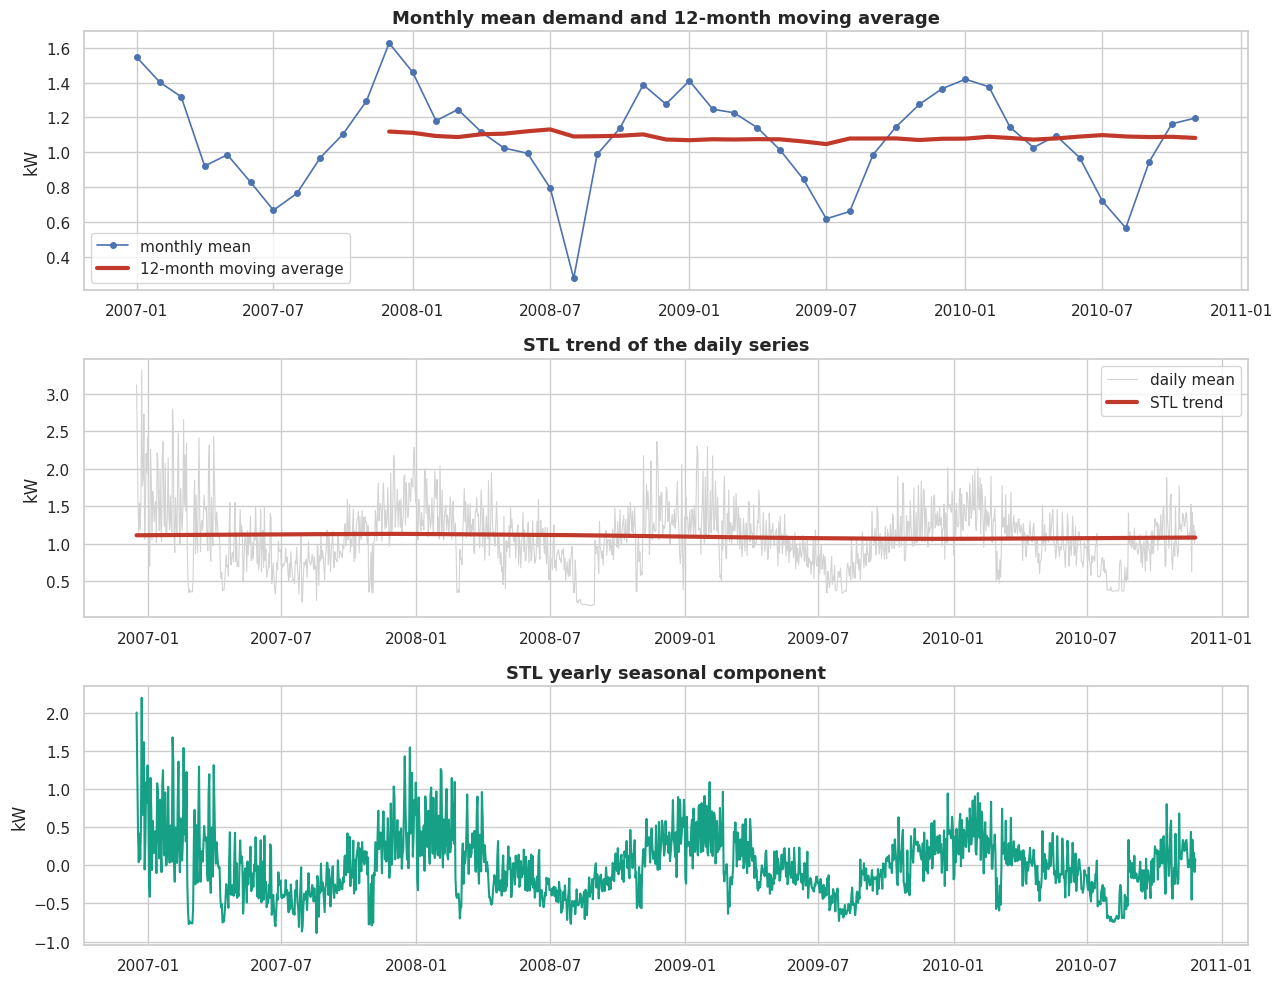

In [7]:
y = hourly["Global_active_power"]
monthly = y.resample("MS").mean().loc["2007-01":]          # drop the half-month Dec 2006
daily = y.resample("D").mean()

# (b) fair yearly comparison: same months (Jan-Nov) in every year
yearly = y[y.index.month <= 11].loc["2007":].groupby(y[y.index.month <= 11].loc["2007":].index.year).mean()
print("Mean demand over Jan-Nov of each year (kW):"); print(yearly.round(3).to_string())
print("Change vs previous year (%):"); print((yearly.pct_change() * 100).round(1).to_string())

# (c) STL decomposition on daily data (yearly seasonality)
stl = STL(daily, period=365, robust=True).fit()
t = np.arange(len(stl.trend)); slope, intercept = np.polyfit(t, stl.trend.values, 1)
print(f"\nSTL trend slope: {slope*365:+.3f} kW per year (start {stl.trend.iloc[0]:.2f} -> end {stl.trend.iloc[-1]:.2f} kW)")

# (d) stationarity test on the daily series
adf_stat, adf_p, *_ = adfuller(daily.dropna(), autolag="AIC")
print(f"ADF test on daily mean: statistic={adf_stat:.2f}, p-value={adf_p:.4f}")

fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=False)
ax[0].plot(monthly, marker="o", ms=4, lw=1.2, label="monthly mean"); ax[0].plot(monthly.rolling(12).mean(), lw=3, color="#c0392b", label="12-month moving average")
ax[0].set_title("Monthly mean demand and 12-month moving average"); ax[0].set_ylabel("kW"); ax[0].legend()
ax[1].plot(daily, color="lightgrey", lw=0.8, label="daily mean"); ax[1].plot(stl.trend, color="#c0392b", lw=3, label="STL trend")
ax[1].set_title("STL trend of the daily series"); ax[1].set_ylabel("kW"); ax[1].legend()
ax[2].plot(stl.seasonal, color="#16a085"); ax[2].set_title("STL yearly seasonal component"); ax[2].set_ylabel("kW")
save_show("q1_trend")

**Interpretation**
* **There is no meaningful long-term trend.** Comparing the same months (Jan-Nov) in each year, mean demand is 1.071 (2007), 1.053 (2008), 1.050 (2009) and 1.052 kW (2010): changes of **-1.6%, -0.4% and +0.3%**. The STL trend slope is only **-0.019 kW per year** (1.11 to 1.08 kW), and the 12-month moving average drifts from 1.12 to 1.08 kW over three years (about -3%), a very small change next to the seasonal swings of roughly 0.5 to 1.5 kW.
* The **ADF test rejects a unit root** on the daily series (statistic -3.66, p = 0.0048), so the series is **stationary around a seasonal pattern**: its level does not wander away over time.
* In the plots, the 12-month moving average is almost flat while the monthly mean oscillates strongly; the STL **seasonal component** (bottom panel) is much larger than the trend movement.
* **Modelling consequence:** we do not need differencing or detrending, and training on 2007-2009 and testing on 2010 is reasonable because the average level is similar in both. The structure to capture is **seasonality (daily, weekly, yearly)**, not trend.

### Q2. How does demand change through the day and across the week (weekday vs weekend)?
**Why:** daily and weekly cycles are the strongest signal in household data. Knowing them tells us which calendar features and which lags (24 h, 168 h) will matter.

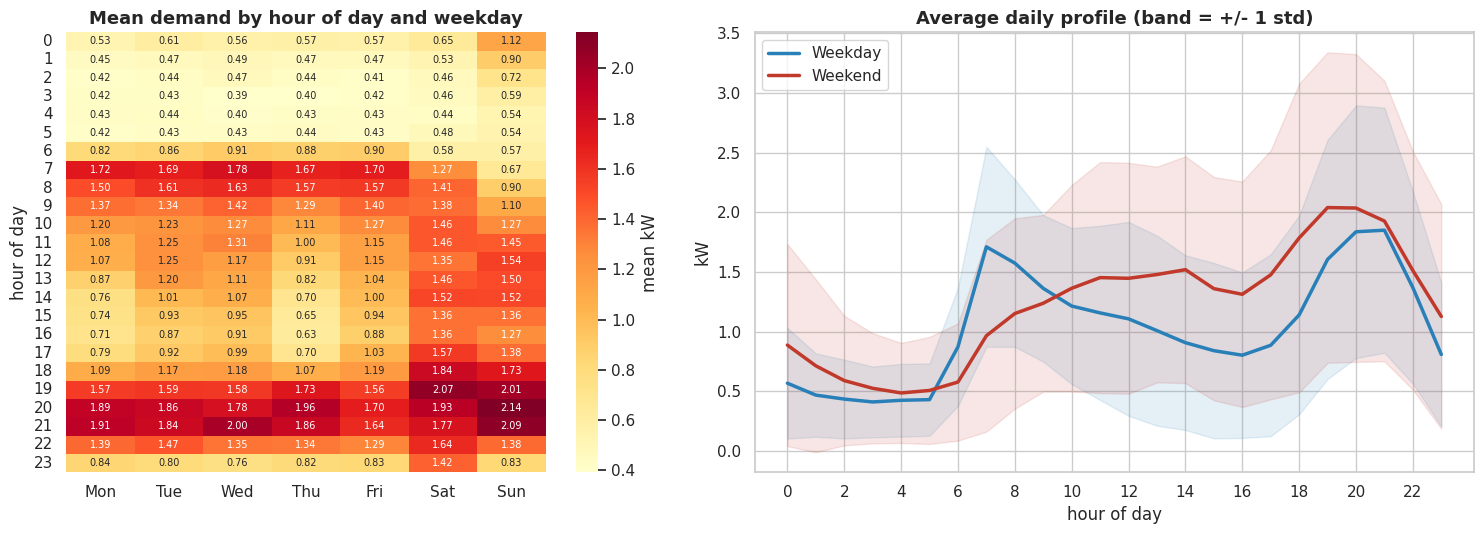

Mean weekday: 1.033 kW | weekend: 1.229 kW | weekend is +19.0%
Peak hour weekday: 21 | weekend: 19
Lowest-demand hour overall: 4 (0.44 kW)


In [8]:
df = hourly.copy(); df["hour"] = df.index.hour; df["dow"] = df.index.dayofweek; df["weekend"] = df["dow"] >= 5
heat = df.pivot_table(values="Global_active_power", index="hour", columns="dow", aggfunc="mean")
heat.columns = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.2]})
sns.heatmap(heat, cmap="YlOrRd", annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"label": "mean kW"}, ax=ax[0])
ax[0].set_title("Mean demand by hour of day and weekday"); ax[0].set_ylabel("hour of day")
for flag, label, col in [(False, "Weekday", "#2980b9"), (True, "Weekend", "#c0392b")]:
    g = df[df.weekend == flag].groupby("hour")["Global_active_power"]
    ax[1].plot(g.mean(), label=label, color=col, lw=2.5); ax[1].fill_between(g.mean().index, g.mean() - g.std(), g.mean() + g.std(), color=col, alpha=0.12)
ax[1].set_title("Average daily profile (band = +/- 1 std)"); ax[1].set_xlabel("hour of day"); ax[1].set_ylabel("kW"); ax[1].legend(); ax[1].set_xticks(range(0, 24, 2))
save_show("q2_daily_weekly")

wk, we = df[~df.weekend]["Global_active_power"], df[df.weekend]["Global_active_power"]
print(f"Mean weekday: {wk.mean():.3f} kW | weekend: {we.mean():.3f} kW | weekend is {(we.mean()/wk.mean()-1)*100:+.1f}%")
print("Peak hour weekday:", g_wd := df[~df.weekend].groupby('hour')['Global_active_power'].mean().idxmax(),
      "| weekend:", df[df.weekend].groupby('hour')['Global_active_power'].mean().idxmax())
print("Lowest-demand hour overall:", df.groupby('hour')['Global_active_power'].mean().idxmin(), f"({df.groupby('hour')['Global_active_power'].mean().min():.2f} kW)")

**Interpretation**
* **Strong daily cycle.** Demand is lowest at night (about 0.41-0.43 kW from 3 to 5 a.m. on weekdays; lowest hour overall: 4 a.m., 0.44 kW) and rises through the day to an **evening peak** (weekday 21:00 = 1.85 kW).
* **Weekdays have a sharp morning peak** at 07:00 (1.71 kW) that reflects the pre-work/school routine, followed by a dip at about 16:00 (0.80 kW) when the house is likely empty, and then the evening rise.
* **Weekends look different:** there is **no sharp 7 a.m. peak** (0.97 kW at 07:00 vs 1.71 on weekdays); demand climbs gradually from 08:00 and stays high all afternoon (1.3-1.5 kW), with a higher evening peak (**2.04 kW at 19:00-20:00**) and higher late-night use (0.89 kW at midnight vs 0.57).
* **Weekend demand is 19% higher overall** (1.229 vs 1.033 kW). The heatmap confirms the same pattern across days: Monday-Friday are alike, Saturday and Sunday are alike.
* **Modelling consequence:** the hour of day and the weekday/weekend distinction carry real information, and the shape of the day differs by day type. This justifies the calendar features (hour, day of week, weekend flag) and the 24 h and 168 h lags.

### Q3. Is there yearly seasonality, and is it consistent across years?
**Why:** if the same months are always high or low, `month` is a strong predictor, and a model trained on 2007-2009 should generalise to 2010.

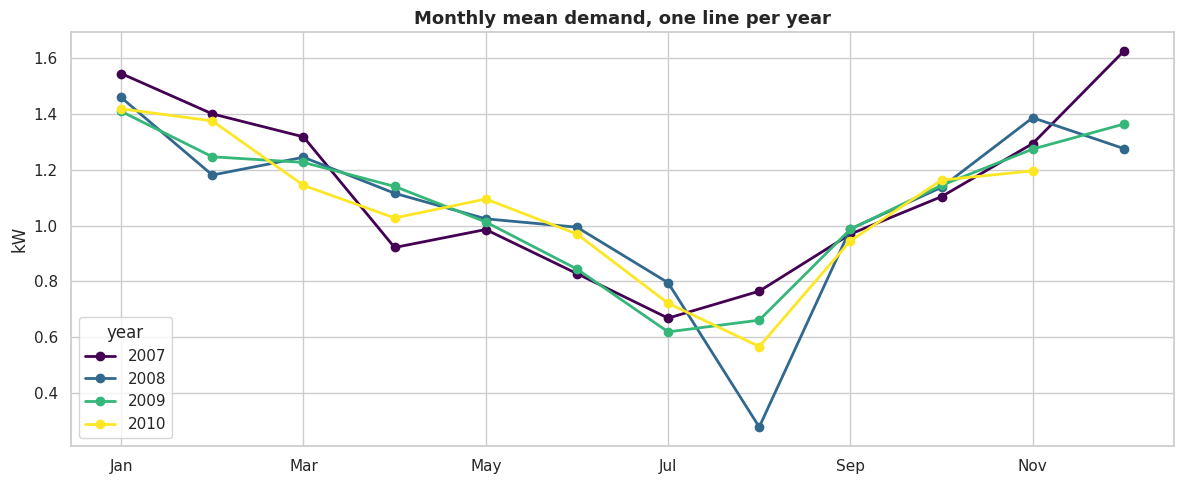

Average across 2007-2009 (kW), ranked:
Jan   1.472
Dec   1.422
Nov   1.319
Feb   1.277
Mar   1.264
Oct   1.129
Apr   1.059
May   1.008
Sep   0.981
Jun   0.889
Jul   0.694
Aug   0.567

Winter (Dec-Feb) 1.390 kW vs Summer (Jun-Aug) 0.716 kW -> winter is 94% higher
August vs July (%), per year: {2007: 15.0, 2008: -65.0, 2009: 7.0, 2010: -22.0}
Correlation between yearly profiles (2007-2009 vs 2010, Jan-Nov): 0.959


In [9]:
m = y.resample("MS").mean().to_frame("kW"); m["year"] = m.index.year; m["month"] = m.index.month
piv = m.pivot(index="month", columns="year", values="kW")
piv.index = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
fig, ax = plt.subplots(figsize=(12, 5))
piv.drop(columns=2006).plot(marker="o", lw=2, ax=ax, cmap="viridis")
ax.set_title("Monthly mean demand, one line per year"); ax.set_ylabel("kW"); ax.set_xlabel("")
ax.legend(title="year")
save_show("q3_monthly_seasonality")

p = piv.drop(columns=2006)
print("Average across 2007-2009 (kW), ranked:"); print(p[[2007, 2008, 2009]].mean(axis=1).sort_values(ascending=False).round(3).to_string())
winter = p[[2007, 2008, 2009]].loc[["Jan", "Feb", "Dec"]].mean().mean(); summer = p[[2007, 2008, 2009]].loc[["Jun", "Jul", "Aug"]].mean().mean()
print(f"\nWinter (Dec-Feb) {winter:.3f} kW vs Summer (Jun-Aug) {summer:.3f} kW -> winter is {(winter/summer-1)*100:.0f}% higher")
print("August vs July (%), per year:", ((p.loc["Aug"] / p.loc["Jul"] - 1) * 100).round(0).to_dict())
print("Correlation between yearly profiles (2007-2009 vs 2010, Jan-Nov):", round(np.corrcoef(p[[2007, 2008, 2009]].iloc[:11].mean(axis=1), p[2010].iloc[:11])[0, 1], 3))

**Interpretation**
* **Clear yearly seasonality:** the average of 2007-2009 ranks **January (1.47 kW), December (1.42) and November (1.32) highest** and **August (0.57), July (0.69) and June (0.89) lowest**. Winter (Dec-Feb) averages 1.39 kW versus 0.72 kW in summer, so **winter demand is 94% higher**, consistent with heating, lighting and more time at home in the cold months.
* **The seasonal shape is consistent from year to year.** The yearly lines in the plot follow the same U-shape, and the correlation between the average 2007-2009 monthly profile and 2010 (Jan-Nov) is **0.96**. That supports using `month` as a feature and testing on 2010.
* **Exception worth noting:** the summer dip is not uniform. **August 2008 (0.28 kW) is extremely low**, about 65% below July of that year, whereas August 2007 and 2009 were close to July (+15% and +7%). A very low August usually means the household was away on holiday, which is a one-off behaviour the model cannot predict from past consumption alone.
* **Modelling consequence:** yearly seasonality is strong, but with only 3 training years each month is seen 3 times; unusual months like Aug 2008 add noise that no model can remove.

### Q4. (Lagged features) Are there lag effects: how much does past demand tell us about the next hour?
**Why:** this is the foundation of forecasting. If demand at *t* correlates strongly with demand at *t-1*, *t-24*, *t-168*, then lag features are informative inputs.
**Method:** (a) autocorrelation (ACF) and partial autocorrelation (PACF) up to 8 days, (b) correlation at hand-picked lags, (c) scatter plots of demand vs its lag.

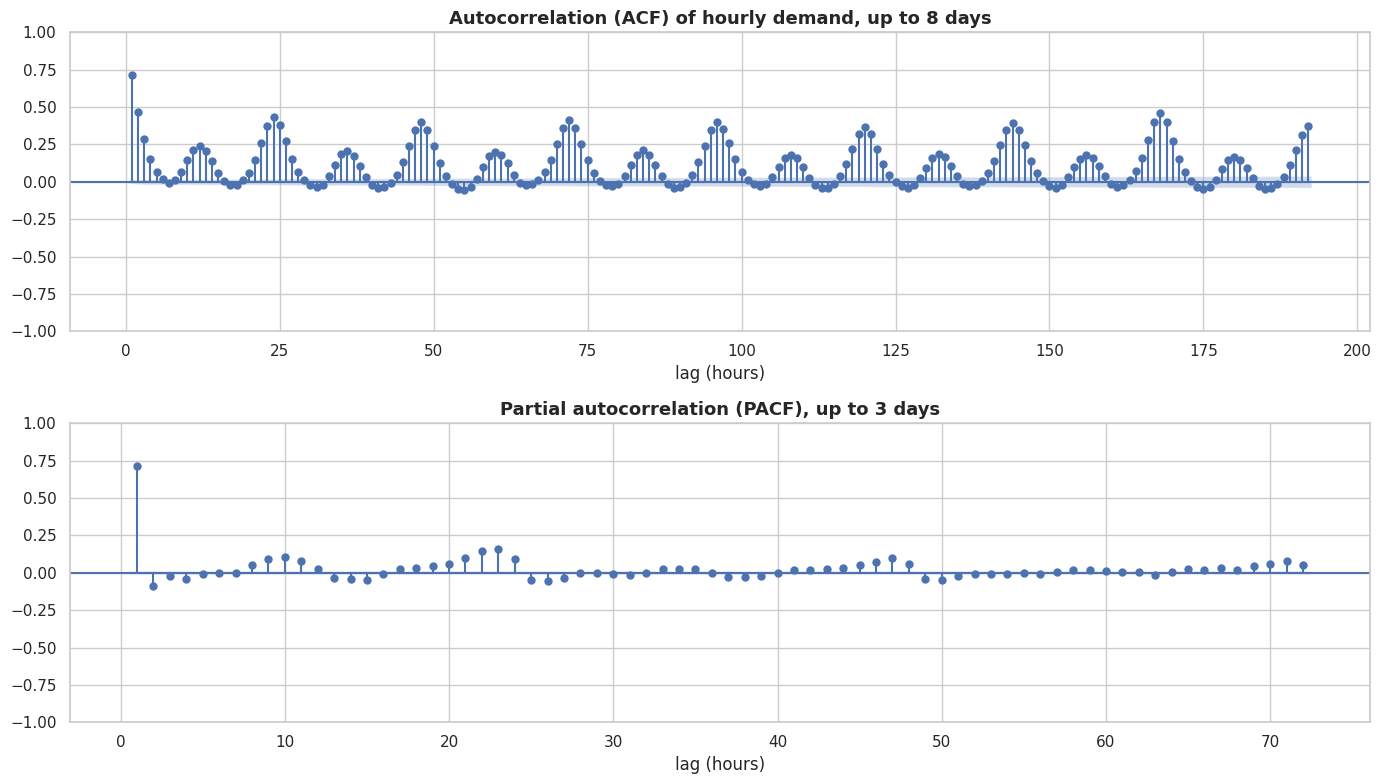

,1,2,3,6,12,24,48,72,168
correlation with demand L hours ago,0.713,0.466,0.287,0.018,0.240,0.436,0.402,0.413,0.466


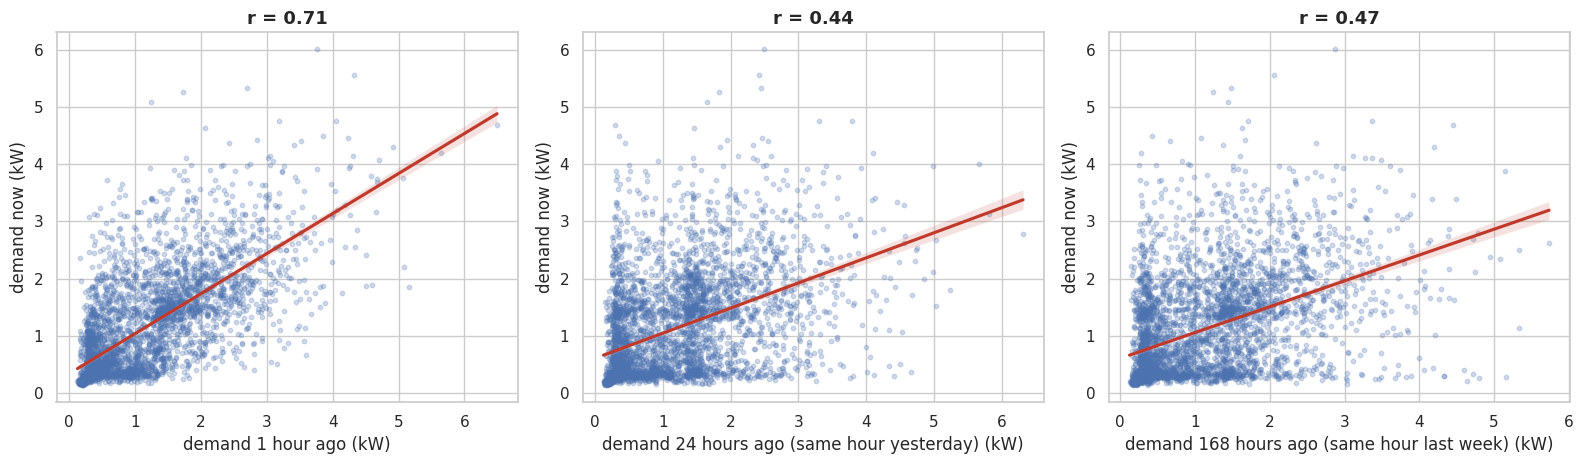

In [10]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8))
plot_acf(y, lags=24 * 8, ax=ax[0], zero=False, alpha=0.05); ax[0].set_title("Autocorrelation (ACF) of hourly demand, up to 8 days")
plot_pacf(y, lags=72, ax=ax[1], zero=False, method="ywm"); ax[1].set_title("Partial autocorrelation (PACF), up to 3 days")
for a in ax: a.set_xlabel("lag (hours)")
save_show("q4_acf_pacf")

lags = [1, 2, 3, 6, 12, 24, 48, 72, 168]
lag_corr = pd.Series({L: y.corr(y.shift(L)) for L in lags}, name="correlation with demand L hours ago")
display(lag_corr.to_frame().T)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
samp = pd.DataFrame({"y": y, "lag1": y.shift(1), "lag24": y.shift(24), "lag168": y.shift(168)}).dropna().sample(4000, random_state=42)
for a, (c, lab) in zip(ax, [("lag1", "1 hour ago"), ("lag24", "24 hours ago (same hour yesterday)"), ("lag168", "168 hours ago (same hour last week)")]):
    sns.regplot(x=samp[c], y=samp["y"], ax=a, scatter_kws={"alpha": .25, "s": 10}, line_kws={"color": "#c0392b"})
    a.set_title(f"r = {y.corr(y.shift(int(c[3:]))):.2f}"); a.set_xlabel(f"demand {lab} (kW)"); a.set_ylabel("demand now (kW)")
save_show("q4_lag_scatter")

**Interpretation**
* **Strongest dependence is on the previous hour:** correlation with demand 1 hour ago is **0.71** (about half of the variance). It decays quickly: **0.47 at 2 h, 0.29 at 3 h**, and about **0.02 at 6 h** (a 6-hour shift usually moves between very different parts of the day, e.g. morning vs afternoon).
* **Daily and weekly echoes:** the ACF rises again at **12 h (0.24), 24 h (0.44) and stays near 0.40 at 48, 72 and 96 h**, with the **weekly lag (168 h) the highest of all long lags (0.46)**, even above 24 h. The ACF never dies out within 8 days: the household repeats its day-shape every day and especially every week.
* **PACF (direct effect of each lag after removing the shorter lags):** lag 1 dominates (0.71); small but significant positive spikes appear around lags 9-11, **21-24** (0.10-0.16) and 46-48, confirming the daily rhythm is a direct effect and not just carried through lag 1.
* The scatter plots show the same story: a tight, clearly positive cloud for 1 h ago (r = 0.71) and looser clouds for yesterday and last week (r = 0.44 and 0.47), still positive.
* **Modelling consequence:** include the last few hours (1, 2, 3 h) for momentum, plus **12, 24, 48 and 168 h** lags for the daily and weekly rhythm. These are exactly the lags used in our feature table.

### Q5. (Moving averages) Do moving averages reveal the underlying pattern, and which window is the best predictor of the next hour?
**Why:** raw hourly data is jagged. Moving averages (a) smooth noise so trends and cycles are visible and (b) are cheap, robust features for models. Different windows capture different time scales, so we test several.
**Method:** (a) overlay 24-hour and 7-day moving averages on raw data, (b) use each moving average of the *previous* hours as a naive forecast of the next hour and compare RMSE and correlation (using `shift(1)` so there is **no leakage** of the value we are predicting).

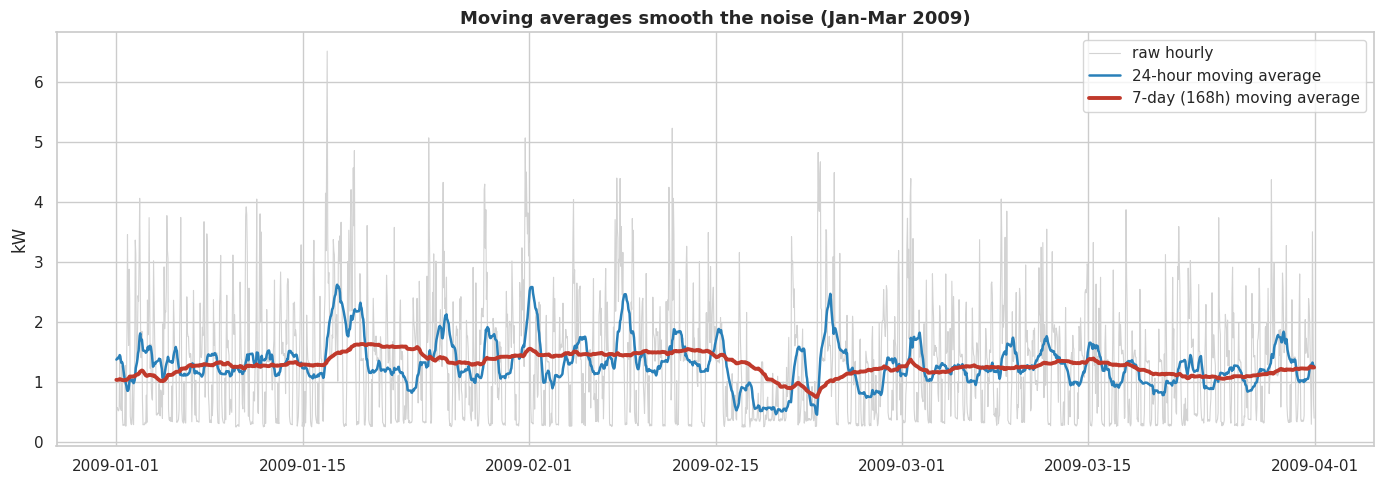

,corr_with_next_hour,RMSE_as_forecast
predictor,,
MA3h,0.558,0.788
MA6h,0.379,0.880
MA12h,0.336,0.863
MA24h,0.351,0.839
MA48h,0.332,0.842
MA168h,0.323,0.842
MA336h,0.302,0.849
lag1h (single value),0.710,0.677
lag24h (single value),0.438,0.944


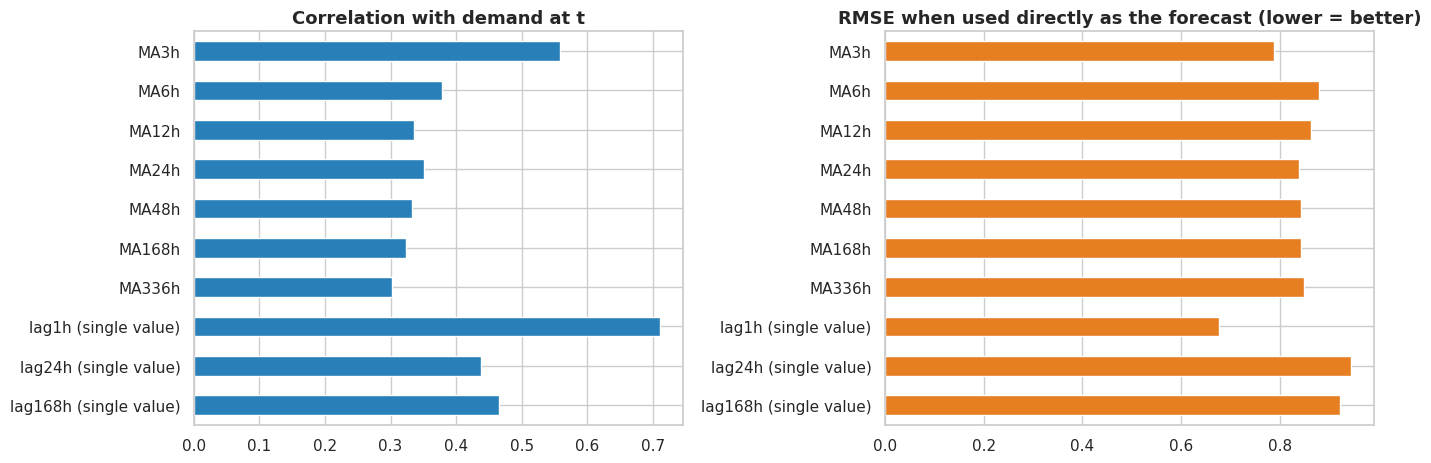

In [11]:
win = slice("2009-01-01", "2009-03-31")
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y.loc[win], color="lightgrey", lw=0.8, label="raw hourly")
ax.plot(y.rolling(24).mean().loc[win], color="#2980b9", lw=1.8, label="24-hour moving average")
ax.plot(y.rolling(168).mean().loc[win], color="#c0392b", lw=2.8, label="7-day (168h) moving average")
ax.set_title("Moving averages smooth the noise (Jan-Mar 2009)"); ax.set_ylabel("kW"); ax.legend()
save_show("q5_moving_average_smoothing")

valid = y.index[337:]
rows = []
for w in [3, 6, 12, 24, 48, 168, 336]:
    ma = y.rolling(w).mean().shift(1).loc[valid]
    rows.append({"predictor": f"MA{w}h", "corr_with_next_hour": np.corrcoef(y.loc[valid], ma)[0, 1], "RMSE_as_forecast": np.sqrt(np.mean((y.loc[valid] - ma) ** 2))})
for L in (1, 24, 168):
    p_ = y.shift(L).loc[valid]
    rows.append({"predictor": f"lag{L}h (single value)", "corr_with_next_hour": np.corrcoef(y.loc[valid], p_)[0, 1], "RMSE_as_forecast": np.sqrt(np.mean((y.loc[valid] - p_) ** 2))})
ma_tbl = pd.DataFrame(rows).set_index("predictor"); display(ma_tbl)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ma_tbl["corr_with_next_hour"].plot(kind="barh", ax=ax[0], color="#2980b9"); ax[0].set_title("Correlation with demand at t"); ax[0].invert_yaxis()
ma_tbl["RMSE_as_forecast"].plot(kind="barh", ax=ax[1], color="#e67e22"); ax[1].set_title("RMSE when used directly as the forecast (lower = better)"); ax[1].invert_yaxis()
for a in ax: a.set_ylabel("")
save_show("q5_moving_average_predictive_power")

**Interpretation**
* **Smoothing:** raw hourly demand in Jan-Mar 2009 is jagged (spikes up to 6.5 kW, std 0.95), while the **24 h moving average** (range 0.46-2.63 kW) removes the hourly noise but keeps day-to-day variation, and the **7-day moving average** (range 0.75-1.63 kW) shows the slow level of consumption: it stays around 1.2-1.6 kW for most of the quarter but drops to about **0.75 kW in the third week of February**, a low-use week (probably an absence) that is hard to see in the raw noise.
* **Predictive power for the next hour:** as a stand-alone forecast, **the last single value (lag 1) is best** (correlation 0.71, RMSE 0.68 kW). Short averages are worse (**MA 3 h: correlation 0.56, RMSE 0.79**) and longer averages are weaker still (MA 6 h to 14 days: correlation about 0.30-0.38, RMSE 0.84-0.88). The ranking is clear: **the more recent information is, the more predictive it is**, and averaging over long windows throws away the timing of the next hour.
* **Why still use moving averages?** They summarise the *recent level* and, with the rolling standard deviation, the *recent volatility*. They are complementary to lags rather than replacements. We test this honestly in the ablation (Experiment E4): adding them improved test RMSE only slightly (0.4841 to 0.4832), because the lag features (1, 2, 3, 6, 12, 24, 48, 168 h) already carry most of that information.
* **Modelling consequence:** moving averages are good for *understanding and smoothing* the series; for one-hour-ahead prediction the freshest lags matter most.

### Q6. Do the other measured variables (voltage, current, reactive power, sub-meters) correlate with demand?
**Why:** the assignment asks whether external variables correlate with the target. It also tells us which of them are worth feeding the model, *and* which are too redundant to add information.
**Method:** correlation heatmap at the same hour, plus the correlation of each variable's **previous-hour** value with the current target (the only version available at forecast time).

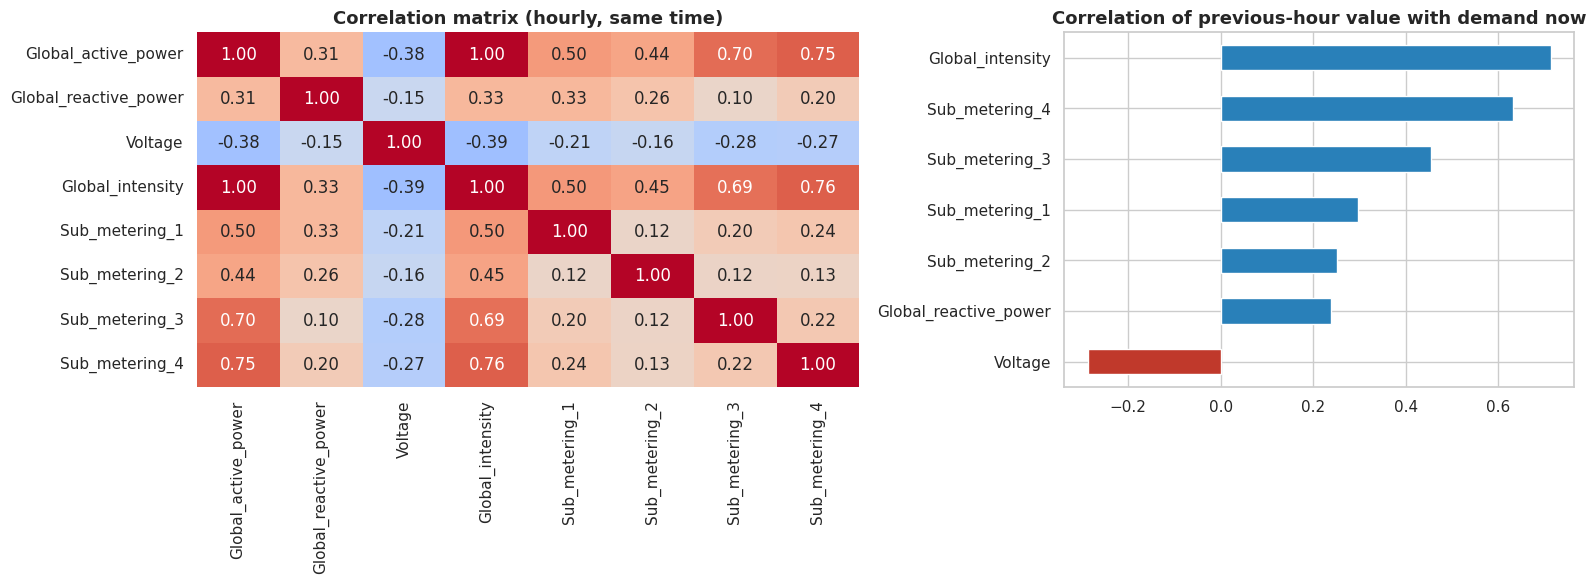

Same-hour correlation with Global_active_power:
Global_intensity         0.999
Sub_metering_4           0.755
Sub_metering_3           0.696
Sub_metering_1           0.496
Sub_metering_2           0.440
Global_reactive_power    0.313
Voltage                 -0.379


In [12]:
corr = hourly[cols].corr()
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax[0], cbar=False)
ax[0].set_title("Correlation matrix (hourly, same time)")
lag1 = pd.Series({c: hourly["Global_active_power"].corr(hourly[c].shift(1)) for c in cols if c != "Global_active_power"}).sort_values()
lag1.plot(kind="barh", ax=ax[1], color=["#c0392b" if v < 0 else "#2980b9" for v in lag1]); ax[1].set_title("Correlation of previous-hour value with demand now")
save_show("q6_correlations")
print("Same-hour correlation with Global_active_power:"); print(corr["Global_active_power"].drop("Global_active_power").sort_values(ascending=False).round(3).to_string())

**Interpretation**
* **`Global_intensity` (current) correlates 0.999 with active power at the same hour.** This is physics: power is roughly voltage x current (the correlation of P/V with intensity is 0.9996). It is the same quantity measured differently, so it cannot be used as a *same-time* predictor (it would not be known before the target). Its *previous-hour* value (0.714) is practically equivalent to the lag-1 demand (0.713).
* **Sub-meters:** the unmetered remainder (`Sub_metering_4`, r = 0.76) and the **water heater / AC (`Sub_metering_3`, r = 0.70)** move most with total demand, followed by the kitchen (0.50) and laundry (0.44). Their previous-hour values keep useful correlations (0.63, 0.46, 0.30, 0.25).
* **`Voltage` is negatively correlated (-0.38; -0.29 at lag 1):** when the household draws more current, the supply voltage dips slightly, which is consistent with voltage drop across the supply line. It is a weak but real signal. **Reactive power** is weakly positive (0.31).
* The heatmap also shows the sub-meters are only mildly correlated with each other: they track *different* appliances, so each adds distinct information.
* **Modelling consequence:** the strongest external signals are previous-hour current and the sub-meters; we include their lag-1 values. Our ablation shows they are worth about 0.02 kW of RMSE.

### Q7. Which parts of the house drive demand, and at what time of day?
**Why:** the three sub-meters plus our engineered `Sub_metering_4` (everything not metered) split total consumption into zones. This explains *where* the peaks come from, and justifies using the sub-meters as features.
**Method:** share of total energy per zone, and the average hourly profile of each zone.

Share of total active energy (%):
Kitchen              6.200
Laundry              7.100
Water heater / AC   35.600
Other (unmetered)   51.100


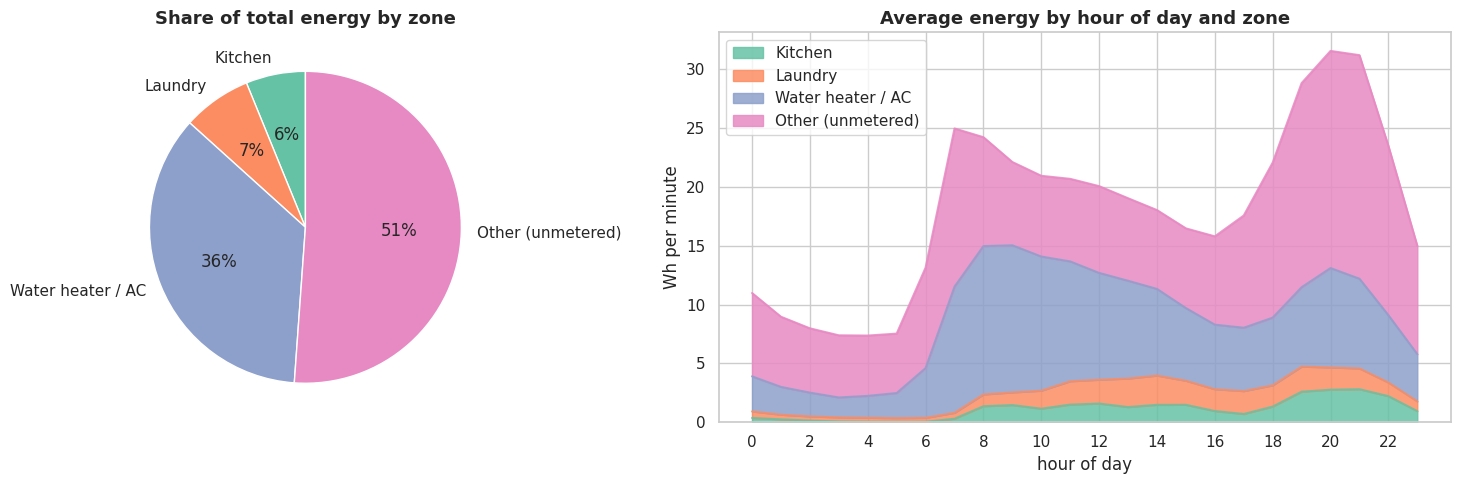

Peak hour per zone: {'Kitchen': 21, 'Laundry': 14, 'Water heater / AC': 8, 'Other (unmetered)': 21}


In [13]:
zones = {"Sub_metering_1": "Kitchen", "Sub_metering_2": "Laundry", "Sub_metering_3": "Water heater / AC", "Sub_metering_4": "Other (unmetered)"}
total = hourly[list(zones)].sum()
share = (total / total.sum() * 100).rename(index=zones); print("Share of total active energy (%):"); print(share.round(1).to_string())

prof = hourly[list(zones)].groupby(hourly.index.hour).mean().rename(columns=zones)
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.6]})
ax[0].pie(share, labels=share.index, autopct="%1.0f%%", startangle=90, colors=sns.color_palette("Set2"), wedgeprops={"edgecolor": "white"})
ax[0].set_title("Share of total energy by zone")
prof.plot.area(ax=ax[1], alpha=0.85, color=sns.color_palette("Set2")); ax[1].set_title("Average energy by hour of day and zone"); ax[1].set_xlabel("hour of day"); ax[1].set_ylabel("Wh per minute"); ax[1].set_xticks(range(0, 24, 2))
save_show("q7_submetering")
print("Peak hour per zone:", prof.idxmax().to_dict())

**Interpretation**
* **Where the energy goes:** the **unmetered remainder is 51%** of active energy (lighting, entertainment, electronics and other loads not on sub-meters 1-3), the **water heater / air conditioner is 36%**, **laundry 7%** and **kitchen 6%**. Two thirds or more of the household's energy therefore does not come from the kitchen or laundry appliances people usually blame.
* **When each zone peaks:** the water heater/AC peaks at **08:00** (consistent with the morning hot-water demand and the weekday morning peak in Q2), the laundry at **14:00**, and the kitchen and the unmetered remainder at **21:00**. The unmetered load more than triples from its night level (about 5 Wh/min at 3-5 a.m.) to about 17-19 Wh/min between 19:00 and 21:00, so **the evening peak is driven mostly by the unmetered remainder**, with the kitchen adding to it.
* The stacked area chart also shows the water-heater/AC zone as a large, steady block through the day: a big, predictable part of demand.
* **Modelling consequence:** zone-level readings explain *why* demand peaks when it does and justify the sub-meter lag features; they also suggest the evening peak (the hardest hours to forecast, see diagnostics) is driven by many small, unmetered devices.

## 5. Feature engineering
**What:** convert the hourly series into a supervised-learning table (one row per hour) where each row holds *past* information and the target is the *current* hour.
**Why each group of features**

| Group | Features | Reason (from our analysis) |
|---|---|---|
| Lagged target | `lag_1, 2, 3, 6, 12, 24, 48, 168` | ACF/PACF showed strong dependence on the last hours and on same-hour-yesterday / last-week (Q4) |
| Moving averages | `roll_mean_3, 6, 24, 168`, `roll_std_24` | Smoothed recent level and volatility (Q5) |
| Other sensors (previous hour) | Voltage, reactive power, intensity, `Sub_metering_1-4` (lag 1) | Correlated with demand (Q6, Q7) |
| Calendar | hour, day-of-week, month, weekend flag, sin/cos encodings | Strong daily / weekly / yearly cycles (Q2, Q3). Sin/cos make hour 23 and hour 0 "neighbours" |

**Leakage guard:** every feature is built from `shift(1)` or older, so the model never sees the value it predicts. Rolling windows are computed on `y.shift(1)`.

In [14]:
print(inspect.getsource(pp.build_features))

feat = pp.build_features(hourly).dropna()          # first 168 hours have no full lag history
FEATURES = pp.feature_columns()
print(f"Supervised table: {feat.shape[0]:,} rows x {len(FEATURES)} features | {feat.index.min()} -> {feat.index.max()}")
feat.head(3).T

def build_features(hourly):
    """
    Supervised table for one-step-ahead forecasting: predict Global_active_power at hour t
    using ONLY information available up to hour t-1 (every feature is shifted >= 1).
    """
    y = hourly[TARGET]
    out = pd.DataFrame(index=hourly.index)
    out[TARGET] = y

    for L in TARGET_LAGS:                                   # lagged features
        out[f"lag_{L}"] = y.shift(L)
    for w in ROLL_WINDOWS:                                  # moving averages (of the PAST w hours)
        out[f"roll_mean_{w}"] = y.shift(1).rolling(w).mean()
    out["roll_std_24"] = y.shift(1).rolling(24).std()

    for c in EXOG_COLS:                                     # other sensors, previous hour
        out[f"{c}_lag1"] = hourly[c].shift(1)

    idx = out.index                                         # calendar features (known in advance)
    out["hour"] = idx.hour
    out["dayofweek"] = idx.dayofweek
    out["month"] = idx.month
    out["is_weekend"] = (idx.day

datetime,2006-12-23 17:00:00,2006-12-23 18:00:00,2006-12-23 19:00:00
Global_active_power,5.453,3.879,4.118
lag_1,4.349,5.453,3.879
lag_2,4.049,4.349,5.453
lag_3,3.758,4.049,4.349
lag_6,3.159,2.929,3.406
lag_12,2.229,1.649,4.023
lag_24,1.497,2.687,3.938
lag_48,1.753,2.443,2.197
lag_168,4.223,3.632,3.400
roll_mean_3,4.052,4.617,4.560


## 6. Model training
### 6.1 Train / test split
**Time-ordered split, never random.** Shuffling would let the model "peek" at the future (e.g. train on Tuesday 10:00 and test on Tuesday 09:00 and 11:00).
* **Train:** Dec 2006 - Dec 2009 (~3 years, every season seen 3 times)
* **Test:** Jan 2010 - Nov 2010 (completely unseen, ~11 months)
* **Hyperparameter tuning** uses `TimeSeriesSplit` *inside* the training period (each fold trains on the past and validates on the following block). The test set is only used once at the end.

In [15]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
from scipy.stats import loguniform

TARGET = pp.TARGET
train, test = feat.loc[:"2009-12-31"], feat.loc["2010-01-01":]
X_train, y_train, X_test, y_test = train[FEATURES], train[TARGET], test[FEATURES], test[TARGET]
print(f"Train: {len(train):,} h ({train.index.min():%Y-%m-%d} -> {train.index.max():%Y-%m-%d}) | Test: {len(test):,} h ({test.index.min():%Y-%m-%d} -> {test.index.max():%Y-%m-%d})")

tscv = TimeSeriesSplit(n_splits=4)
def metrics(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)), "MAE": mean_absolute_error(y_true, y_pred), "R2": r2_score(y_true, y_pred)}

experiments = []
def log(name, model_desc, features_desc, params, cv_rmse, y_pred, fit_s=None):
    m = metrics(y_test, y_pred)
    experiments.append({"Experiment": name, "Model": model_desc, "Features": features_desc, "Best hyperparameters": params,
                        "CV RMSE (train)": cv_rmse, "Test RMSE": m["RMSE"], "Test MAE": m["MAE"], "Test R2": m["R2"], "Tuning time (s)": fit_s})

Train: 26,503 h (2006-12-23 -> 2009-12-31) | Test: 7,918 h (2010-01-01 -> 2010-11-26)


### 6.2 Baselines (no learning)
**Why:** a model is only impressive if it beats simple rules. *Persistence* ("next hour = this hour") and *seasonal naive* ("same hour yesterday / last week") set the bar.

In [16]:
for name, col in [("E0a Persistence", "lag_1"), ("E0b Seasonal naive (24h)", "lag_24"), ("E0c Seasonal naive (168h)", "lag_168")]:
    log(name, "Rule (no training)", col, "-", np.nan, X_test[col].values)
pd.DataFrame(experiments)[["Experiment", "Test RMSE", "Test MAE", "Test R2"]]

,Experiment,Test RMSE,Test MAE,Test R2
0,E0a Persistence,0.619,0.408,0.372
1,E0b Seasonal naive (24h),0.818,0.554,-0.097
2,E0c Seasonal naive (168h),0.815,0.554,-0.089


### 6.3 Experiment 1 - Ridge regression (linear baseline, tuned)
**Why:** linear models are the classical reference for forecasting with lag features: fast, interpretable. Features are standardised (fit on train only) because Ridge penalises coefficient size. We tune the regularisation strength `alpha`.

In [17]:
t0 = time.time()
ridge = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
                     cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=1).fit(X_train, y_train)
log("E1 Ridge (tuned)", "Ridge regression", "All 30 features", ridge.best_params_, -ridge.best_score_, ridge.predict(X_test), time.time() - t0)
print("Best:", ridge.best_params_, "| CV RMSE:", round(-ridge.best_score_, 4))

Best: {'ridge__alpha': 100} | CV RMSE: 0.5756


### 6.4 Experiment 2 - Random Forest (non-linear, tuned)
**Why:** forests capture non-linear effects and interactions (e.g. "evening AND weekend AND winter") without scaling. We tune depth, leaf size and feature sampling (the main levers against overfitting) with randomized search over time-aware folds.

In [18]:
t0 = time.time()
rf = RandomizedSearchCV(RandomForestRegressor(random_state=42, n_jobs=1),
        {"n_estimators": [100, 200], "max_depth": [8, 12, 16], "min_samples_leaf": [3, 5, 10], "max_features": [0.3, 0.5, 1.0]},
        n_iter=8, cv=TimeSeriesSplit(n_splits=3), scoring="neg_root_mean_squared_error", random_state=42, n_jobs=1).fit(X_train, y_train)
log("E2 Random Forest (tuned)", "RandomForestRegressor", "All 30 features", rf.best_params_, -rf.best_score_, rf.predict(X_test), time.time() - t0)
print("Best:", rf.best_params_, "| CV RMSE:", round(-rf.best_score_, 4), f"| {time.time()-t0:.0f}s")

Best: {'n_estimators': 200, 'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 12} | CV RMSE: 0.5282 | 448s


### 6.5 Experiment 3 - Gradient Boosting (HistGradientBoosting, tuned)
**Why:** boosting builds trees sequentially, each fixing the previous errors; it is typically the strongest classical model on tabular lag features. We tune learning rate, number of iterations, tree size, minimum leaf size and L2 regularisation.

In [19]:
t0 = time.time()
hgb = RandomizedSearchCV(HistGradientBoostingRegressor(random_state=42),
        {"learning_rate": loguniform(0.01, 0.2), "max_iter": [200, 400, 600], "max_depth": [3, 5, 8, None],
         "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [20, 50, 100], "l2_regularization": [0, 0.1, 1, 10]},
        n_iter=20, cv=tscv, scoring="neg_root_mean_squared_error", random_state=42, n_jobs=1).fit(X_train, y_train)
best_hgb_params = {k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in hgb.best_params_.items()}
log("E3 HistGradientBoosting (tuned)", "HistGradientBoostingRegressor", "All 30 features", best_hgb_params, -hgb.best_score_, hgb.predict(X_test), time.time() - t0)
print("Best:", best_hgb_params, "| CV RMSE:", round(-hgb.best_score_, 4), f"| {time.time()-t0:.0f}s")

Best: {'l2_regularization': 0.1, 'learning_rate': 0.0265, 'max_depth': None, 'max_iter': 200, 'max_leaf_nodes': 31, 'min_samples_leaf': 100} | CV RMSE: 0.5262 | 97s


### 6.6 Experiment 4 - Feature ablation (do moving averages and other sensors help?)
**Why:** this tests the conclusions of our analytical questions. We refit the best boosting model (same hyperparameters, so the comparison is fair) with progressively fewer feature groups.

In [20]:
lag_cols = [f"lag_{L}" for L in pp.TARGET_LAGS]
cal_cols = ["hour", "dayofweek", "month", "is_weekend", "hour_sin", "hour_cos", "dow_sin", "dow_cos", "month_sin", "month_cos"]
roll_cols = [f"roll_mean_{w}" for w in pp.ROLL_WINDOWS] + ["roll_std_24"]
exog_cols = [f"{c}_lag1" for c in pp.EXOG_COLS]
sets = {"E4a Lags + calendar only": lag_cols + cal_cols,
        "E4b + moving averages (no other sensors)": lag_cols + cal_cols + roll_cols,
        "E4c Without calendar features": lag_cols + roll_cols + exog_cols}
for name, fs in sets.items():
    t0 = time.time()
    m_ = HistGradientBoostingRegressor(random_state=42, **hgb.best_params_).fit(X_train[fs], y_train)
    log(name, "HistGradientBoosting (E3 params)", f"{len(fs)} features", "same as E3", np.nan, m_.predict(X_test[fs]), time.time() - t0)
print("done")

done


### 6.7 Experiment table
Models are **selected by cross-validation RMSE on the training period** (not by test score) to avoid choosing based on the test set. Test scores show real out-of-sample performance on 2010.

,Experiment,Model,Features,Best hyperparameters,CV RMSE (train),Test RMSE,Test MAE,Test R2,Tuning time (s)
0,E0a Persistence,Rule (no training),lag_1,-,-,0.6191,0.4076,0.3722,-
1,E0b Seasonal naive (24h),Rule (no training),lag_24,-,-,0.8183,0.5538,-0.0969,-
2,E0c Seasonal naive (168h),Rule (no training),lag_168,-,-,0.8154,0.5543,-0.0892,-
3,E1 Ridge (tuned),Ridge regression,All 30 features,{'ridge__alpha': 100},0.5756,0.5182,0.3690,0.5602,0
4,E2 Random Forest (tuned),RandomForestRegressor,All 30 features,"{'n_estimators': 200, 'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 12}",0.5282,0.4646,0.3141,0.6465,448
5,E3 HistGradientBoosting (tuned),HistGradientBoostingRegressor,All 30 features,"{'l2_regularization': 0.1, 'learning_rate': 0.0265, 'max_depth': None, 'max_iter': 200, 'max_leaf_nodes': 31, 'min_samples_leaf': 100}",0.5262,0.4634,0.3158,0.6482,97
6,E4a Lags + calendar only,HistGradientBoosting (E3 params),18 features,same as E3,-,0.4841,0.3346,0.6162,1
7,E4b + moving averages (no other sensors),HistGradientBoosting (E3 params),23 features,same as E3,-,0.4832,0.3322,0.6176,1
8,E4c Without calendar features,HistGradientBoosting (E3 params),20 features,same as E3,-,0.4825,0.3298,0.6186,1


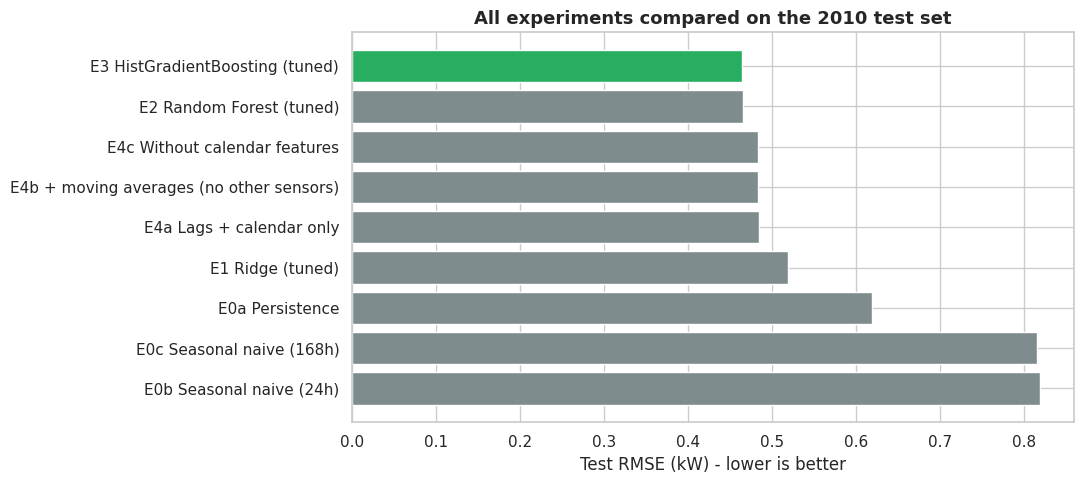

In [21]:
exp = pd.DataFrame(experiments)
exp_show = exp.copy()
exp_show["Best hyperparameters"] = exp_show["Best hyperparameters"].astype(str)
exp_show.to_csv("data/experiment_table.csv", index=False)
display(exp_show.style.format({"CV RMSE (train)": "{:.4f}", "Test RMSE": "{:.4f}", "Test MAE": "{:.4f}", "Test R2": "{:.4f}", "Tuning time (s)": "{:.0f}"}, na_rep="-")
        .background_gradient(subset=["Test RMSE"], cmap="RdYlGn_r").set_properties(**{"text-align": "left"}))

fig, ax = plt.subplots(figsize=(11, 5))
e = exp.sort_values("Test RMSE", ascending=False)
ax.barh(e["Experiment"], e["Test RMSE"], color=["#27ae60" if "E3" in n else "#7f8c8d" for n in e["Experiment"]])
ax.set_xlabel("Test RMSE (kW) - lower is better"); ax.set_title("All experiments compared on the 2010 test set")
save_show("experiment_comparison")

**Interpretation of the experiment table (test period: Jan-Nov 2010)**
* **Baselines:** persistence reaches RMSE 0.619 kW and R2 0.37. The seasonal-naive rules are *worse than predicting the mean* (R2 about -0.09; RMSE 0.82): copying "same hour yesterday / last week" is too unreliable on its own, matching the weak 24 h and 168 h correlations in Q4.
* **E1 Ridge (alpha = 100):** RMSE 0.518, R2 0.56. A linear model on our features already beats persistence by about 16%.
* **E2 Random Forest and E3 HistGradientBoosting:** RMSE **0.465** and **0.463**, R2 0.65, MAE 0.31-0.32. The non-linear models are clearly better than Ridge (about 10% lower RMSE), showing the demand/lag/calendar relationships are non-linear. **E2 and E3 are practically tied** (difference 0.001 kW); we select **E3 because it has the lowest cross-validation RMSE (0.5262 vs 0.5282) and tunes about 5x faster (92 s vs 442 s)**.
* **Overall improvement:** the selected model lowers RMSE from 0.619 to 0.463 (**about -25%**) and MAE from 0.408 to 0.316 (**about -23%**) versus persistence, and raises R2 from 0.37 to 0.65.
* **Ablation (E4):** with identical hyperparameters, lags + calendar only gives RMSE 0.4841; adding moving averages gives 0.4832 (negligible, matching the Q5 finding); removing the calendar features gives 0.4825; the full set gives 0.4634. So the **sensor features (previous-hour current and sub-meters) bring the largest gain (about 0.02 kW)** and calendar features add about 0.02. These are single fits without repeated runs, so differences of about 0.001 should not be over-interpreted.
* **CV vs test error:** CV RMSE (0.53-0.58) is higher than test RMSE (0.46-0.52) because the early folds train on only 1-2 years of data; the test model uses all 3 training years.

### 6.8 Diagnostics of the best model
**Why:** a single score hides *where* the model fails. We inspect predictions over time, residuals, error by hour of day, and which features matter (permutation importance: shuffle one feature and see how much the error grows).

Selected model (lowest CV RMSE): E3 HistGradientBoosting (tuned)


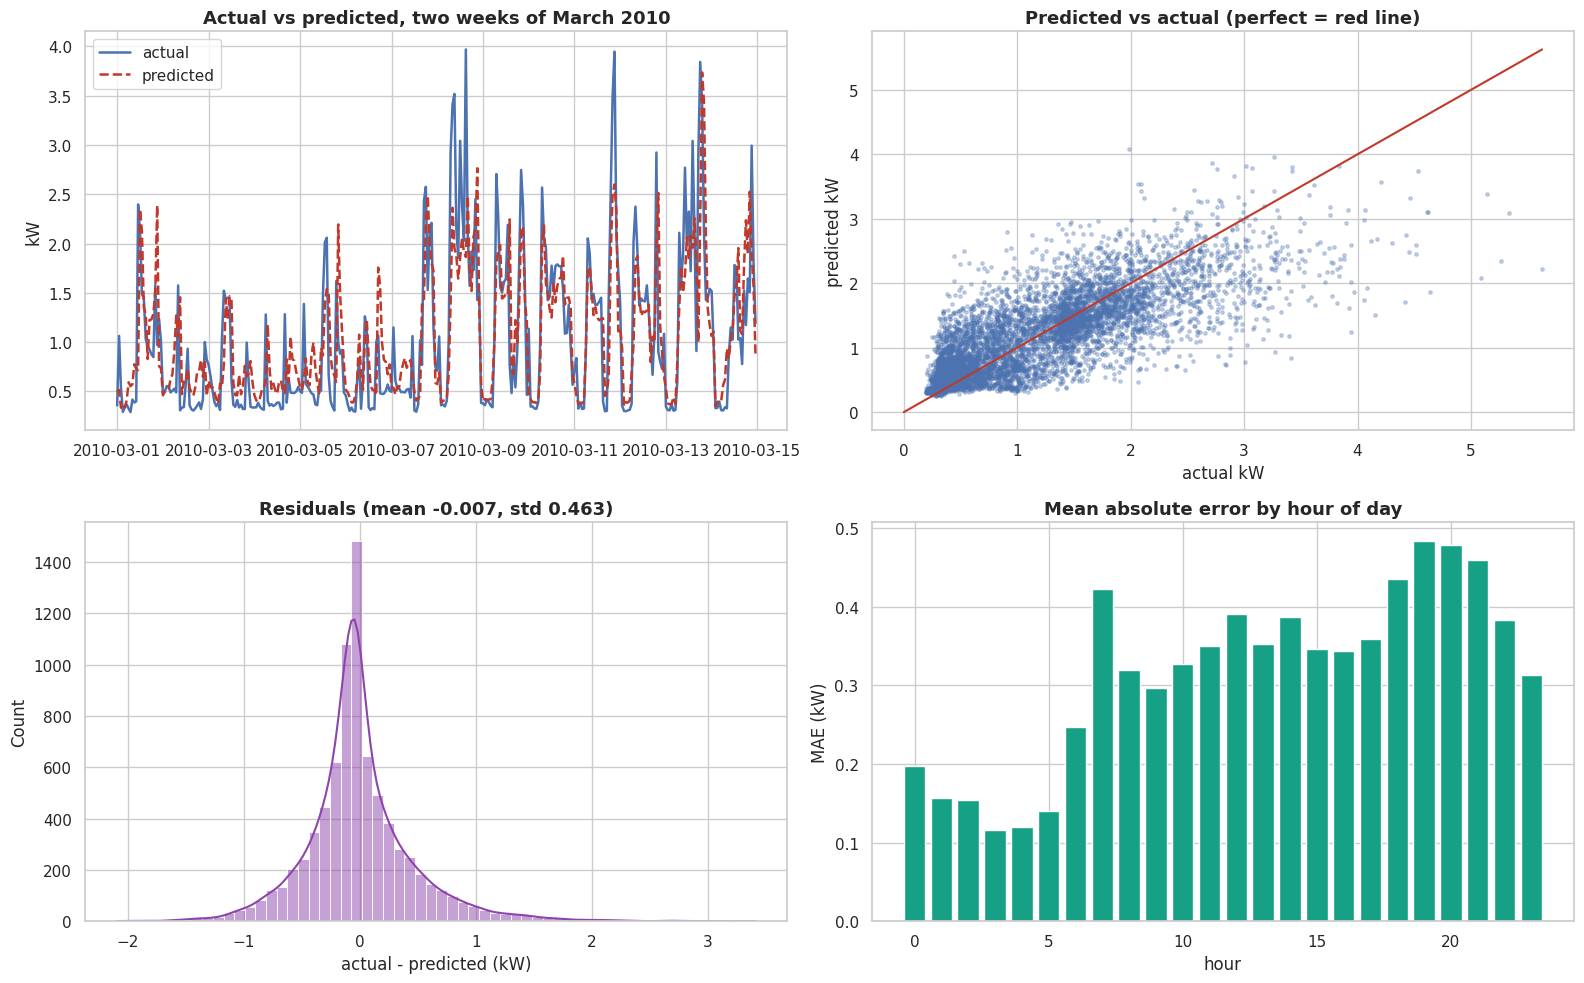

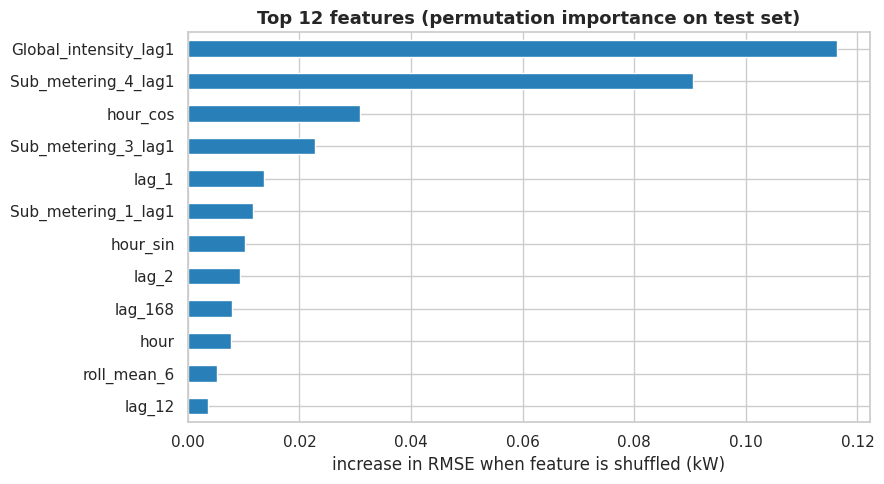

Global_intensity_lag1   0.116
Sub_metering_4_lag1     0.091
hour_cos                0.031
Sub_metering_3_lag1     0.023
lag_1                   0.014
Sub_metering_1_lag1     0.012
hour_sin                0.010
lag_2                   0.009
lag_168                 0.008
hour                    0.008
roll_mean_6             0.005
lag_12                  0.004


In [22]:
cv_models = {"E1 Ridge (tuned)": ridge, "E2 Random Forest (tuned)": rf, "E3 HistGradientBoosting (tuned)": hgb}
best_name = min(cv_models, key=lambda k: -cv_models[k].best_score_)       # selected on CV, not on test
best = cv_models[best_name].best_estimator_
print("Selected model (lowest CV RMSE):", best_name)
pred = pd.Series(best.predict(X_test), index=X_test.index); resid = y_test - pred

fig, ax = plt.subplots(2, 2, figsize=(16, 10))
w = slice("2010-03-01", "2010-03-14")
ax[0, 0].plot(y_test.loc[w], label="actual", lw=1.8); ax[0, 0].plot(pred.loc[w], label="predicted", lw=1.8, ls="--", color="#c0392b")
ax[0, 0].set_title("Actual vs predicted, two weeks of March 2010"); ax[0, 0].set_ylabel("kW"); ax[0, 0].legend()
ax[0, 1].scatter(y_test, pred, s=6, alpha=0.3); lim = [0, max(y_test.max(), pred.max())]; ax[0, 1].plot(lim, lim, color="#c0392b")
ax[0, 1].set_title("Predicted vs actual (perfect = red line)"); ax[0, 1].set_xlabel("actual kW"); ax[0, 1].set_ylabel("predicted kW")
sns.histplot(resid, bins=60, kde=True, ax=ax[1, 0], color="#8e44ad"); ax[1, 0].set_title(f"Residuals (mean {resid.mean():.3f}, std {resid.std():.3f})"); ax[1, 0].set_xlabel("actual - predicted (kW)")
mae_h = resid.abs().groupby(resid.index.hour).mean(); ax[1, 1].bar(mae_h.index, mae_h.values, color="#16a085")
ax[1, 1].set_title("Mean absolute error by hour of day"); ax[1, 1].set_xlabel("hour"); ax[1, 1].set_ylabel("MAE (kW)")
save_show("best_model_diagnostics")

pi = permutation_importance(best, X_test, y_test, n_repeats=3, random_state=42, scoring="neg_root_mean_squared_error", n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9, 5)); imp[::-1].plot(kind="barh", color="#2980b9", ax=ax)
ax.set_title("Top 12 features (permutation importance on test set)"); ax.set_xlabel("increase in RMSE when feature is shuffled (kW)")
save_show("feature_importance")
print(imp.round(4).to_string())

**Interpretation**
* **Overall fit:** the predicted curve follows the actual daily rhythm well, including the day-to-day shape; residuals are centred on zero (mean -0.007 kW) with std 0.46 kW and MAE 0.32 kW.
* **Where it fails:** the model **systematically under-predicts large peaks**. For the 2.2% of test hours above 3 kW, MAE is **1.22 kW** and the average error is **+1.18 kW** (actual higher than predicted). Peaks come from sudden appliance activations that are not visible in the previous hour, which is an inherent limit of one-hour-ahead forecasting from aggregated data. The scatter plot shows the points fanning out below the red line at high demand.
* **By hour of day:** errors are smallest at night (about 0.12 kW at 3 a.m.) and largest in the evening, **18:00-21:00 (0.44-0.48 kW)**, and at 07:00 (0.42 kW), the same hours where Q2 and Q7 showed the biggest and most abrupt load changes.
* **Feature importance:** the previous-hour current (`Global_intensity_lag1`, 0.116) and unmetered load (`Sub_metering_4_lag1`, 0.091) lead, followed by the cyclical hour encoding (`hour_cos`, 0.031), the water heater/AC (0.023) and `lag_1`. **Caution:** `Global_intensity_lag1` and `lag_1` are almost the same signal (correlation about 0.71 with the target, r = 0.9996 with power/voltage), and permutation importance can split or inflate credit between near-duplicate features, so read these as "the previous hour's load level is what matters most", not as a precise ranking.
* **Improvement ideas:** add holiday/school-break features, try an LSTM or multi-step setup, and tune a loss that weights peaks more heavily.

## 7. Save artefacts for the other tasks
* `data/hourly_clean.csv` - the cleaned hourly table (your teammates can load this into MySQL and MongoDB in Task 2, so the whole team uses the **same** cleaned data)
* `models/best_model.joblib` + `models/feature_columns.json` - used by the Task 4 forecast script
* `preprocessing.py` - the pipeline Task 4 must reuse so training and prediction use identical steps

In [23]:
import joblib
hourly.to_csv("data/hourly_clean.csv")
joblib.dump(best, "models/best_model.joblib")
json.dump({"features": FEATURES, "target": TARGET, "model": best_name, "train_end": "2009-12-31",
           "test_metrics": {k: float(v) for k, v in metrics(y_test, pred).items()}}, open("models/feature_columns.json", "w"), indent=2)

# sanity check: reproduce Task 4 style single forecast from the last 200 hours
last = pp.features_for_next_hour(hourly.iloc[-200:])
print("Forecast for", last.index[0], "=", round(float(best.predict(last)[0]), 3), "kW")
print("Saved:", sorted(p.name for p in Path('models').iterdir()), sorted(p.name for p in Path('data').iterdir()))

Forecast for 2010-11-26 22:00:00 = 0.908 kW
Saved: ['best_model.joblib', 'feature_columns.json'] ['experiment_table.csv', 'hourly_clean.csv']


## 8. Conclusion
**What we did.** (1) Understood and validated a 4-year, minute-level dataset; (2) handled missing values with a gap-aware method; (3) answered seven analytical questions, including lag and moving-average analyses; (4) engineered leakage-free features; (5) ran baselines, three tuned model families and a feature ablation, and chose the final model by cross-validation.
**Limitations and next steps.** The forecast horizon is one hour; multi-step forecasting, an LSTM, and holiday features (the household is French, so national holidays and school breaks matter) are natural extensions.

**Key results**
* 3.95 years of minute data, 1.25% missing in 71 gaps (95% in 6 multi-day outages), handled with hourly aggregation plus short-gap interpolation and same-hour-last-week filling.
* Demand has **strong daily, weekly and yearly seasonality and no meaningful trend**; the previous hour is the strongest predictor, with daily/weekly echoes.
* Final model: **HistGradientBoosting**, test RMSE **0.463 kW**, MAE **0.316 kW**, R2 **0.65**, about 25% better than the persistence baseline. Its main weakness is under-predicting sudden evening peaks.